<a href="https://colab.research.google.com/github/100522155/egci463/blob/main/Iris_Data_logistic_Examples.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import Data
    Assume the data is in my(your) drive!!
    You can import the data from data upload

In [57]:
import numpy as np
import pandas as pd
import math as mt
from google.colab import drive
import io
from google.colab import files
uploaded = files.upload()
df = pd.read_csv(io.BytesIO(uploaded["Iris.csv"]))


Saving Iris.csv to Iris.csv


# Show the data content

In [58]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


# Prepare the input data by splitting the data

In [75]:
from sklearn.model_selection import train_test_split
X, X_test, y, y_test = train_test_split(df.iloc[:,1:-1], df.iloc[:,-1], test_size=0.2, random_state=20)

In [76]:
print(X)

     SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
95             5.7           3.0            4.2           1.2
88             5.6           3.0            4.1           1.3
0              5.1           3.5            1.4           0.2
46             5.1           3.8            1.6           0.2
11             4.8           3.4            1.6           0.2
..             ...           ...            ...           ...
22             4.6           3.6            1.0           0.2
75             6.6           3.0            4.4           1.4
137            6.4           3.1            5.5           1.8
15             5.7           4.4            1.5           0.4
99             5.7           2.8            4.1           1.3

[120 rows x 4 columns]


# Logistic Regression

# Create (Select) a Model

In [77]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

#Train the model

In [78]:
model=model.fit(X, y)

# Test the model

In [79]:
y_pred= model.predict(X_test)

y_probs = model.predict_proba(X_test)
y_log_probs = model.predict_log_proba(X_test)

Show the output prediction

In [80]:
print(y_pred)

['Iris-setosa' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-virginica' 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-setosa' 'Iris-setosa' 'Iris-virginica'
 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-virginica' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor']


Log_prob (show the exponantial of the log value)

In [81]:
print(np.exp(y_log_probs))

[[9.83863776e-01 1.61361631e-02 6.10022093e-08]
 [4.33562326e-03 8.61067483e-01 1.34596894e-01]
 [9.71763741e-03 9.30028895e-01 6.02534680e-02]
 [3.14933799e-05 1.78744407e-01 8.21224100e-01]
 [2.26102207e-02 9.55788595e-01 2.16011840e-02]
 [2.96310606e-02 9.23484583e-01 4.68843562e-02]
 [4.84446687e-06 1.86581804e-02 9.81336975e-01]
 [9.81008642e-01 1.89912411e-02 1.16977799e-07]
 [1.31409611e-05 7.89762311e-02 9.21010628e-01]
 [9.75789895e-01 2.42100394e-02 6.51090799e-08]
 [2.48741306e-04 1.81307392e-01 8.18443867e-01]
 [1.61288528e-03 7.92625192e-01 2.05761923e-01]
 [7.44689941e-04 5.09854481e-01 4.89400829e-01]
 [9.84890484e-01 1.51094872e-02 2.85818763e-08]
 [9.76918564e-01 2.30813728e-02 6.29234817e-08]
 [9.44011321e-08 8.38275017e-03 9.91617155e-01]
 [9.92355701e-01 7.64428681e-03 1.21970855e-08]
 [3.84295603e-03 8.84909100e-01 1.11247944e-01]
 [1.58105383e-04 5.75206691e-02 9.42321225e-01]
 [2.01212489e-01 7.94889045e-01 3.89846609e-03]
 [2.78027830e-03 8.53961948e-01 1.432577

In [82]:
print(np.exp(y_log_probs)/np.sum(np.exp(y_log_probs),axis=1)[:,None])

[[9.83863776e-01 1.61361631e-02 6.10022093e-08]
 [4.33562326e-03 8.61067483e-01 1.34596894e-01]
 [9.71763741e-03 9.30028895e-01 6.02534680e-02]
 [3.14933799e-05 1.78744407e-01 8.21224100e-01]
 [2.26102207e-02 9.55788595e-01 2.16011840e-02]
 [2.96310606e-02 9.23484583e-01 4.68843562e-02]
 [4.84446687e-06 1.86581804e-02 9.81336975e-01]
 [9.81008642e-01 1.89912411e-02 1.16977799e-07]
 [1.31409611e-05 7.89762311e-02 9.21010628e-01]
 [9.75789895e-01 2.42100394e-02 6.51090799e-08]
 [2.48741306e-04 1.81307392e-01 8.18443867e-01]
 [1.61288528e-03 7.92625192e-01 2.05761923e-01]
 [7.44689941e-04 5.09854481e-01 4.89400829e-01]
 [9.84890484e-01 1.51094872e-02 2.85818763e-08]
 [9.76918564e-01 2.30813728e-02 6.29234817e-08]
 [9.44011321e-08 8.38275017e-03 9.91617155e-01]
 [9.92355701e-01 7.64428681e-03 1.21970855e-08]
 [3.84295603e-03 8.84909100e-01 1.11247944e-01]
 [1.58105383e-04 5.75206691e-02 9.42321225e-01]
 [2.01212489e-01 7.94889045e-01 3.89846609e-03]
 [2.78027830e-03 8.53961948e-01 1.432577

Show the softmax of the prediction

In [83]:
print(f"{np.array2string(y_probs, formatter={'float': lambda x: f'{x:.2f}'}, separator=', ')}")


[[0.98, 0.02, 0.00],
 [0.00, 0.86, 0.13],
 [0.01, 0.93, 0.06],
 [0.00, 0.18, 0.82],
 [0.02, 0.96, 0.02],
 [0.03, 0.92, 0.05],
 [0.00, 0.02, 0.98],
 [0.98, 0.02, 0.00],
 [0.00, 0.08, 0.92],
 [0.98, 0.02, 0.00],
 [0.00, 0.18, 0.82],
 [0.00, 0.79, 0.21],
 [0.00, 0.51, 0.49],
 [0.98, 0.02, 0.00],
 [0.98, 0.02, 0.00],
 [0.00, 0.01, 0.99],
 [0.99, 0.01, 0.00],
 [0.00, 0.88, 0.11],
 [0.00, 0.06, 0.94],
 [0.20, 0.79, 0.00],
 [0.00, 0.85, 0.14],
 [0.00, 0.28, 0.72],
 [0.00, 0.17, 0.83],
 [0.95, 0.05, 0.00],
 [0.00, 0.62, 0.38],
 [0.05, 0.94, 0.01],
 [0.31, 0.68, 0.00],
 [0.97, 0.03, 0.00],
 [0.00, 0.03, 0.97],
 [0.00, 0.52, 0.48]]


In [85]:
model=model.score(X_test, y_test)
print(model)

0.9333333333333333


# Perform a ROC curve from 2 selected data

ROC of the second line, Iris-versicolor

[1.         1.         1.         1.         1.         1.
 1.         1.         0.81818182 0.63636364 0.36363636 0.
 0.        ]
[0.63333333 0.63333333 0.2        0.1        0.06666667 0.06666667
 0.06666667 0.         0.         0.         0.         0.
 0.        ]


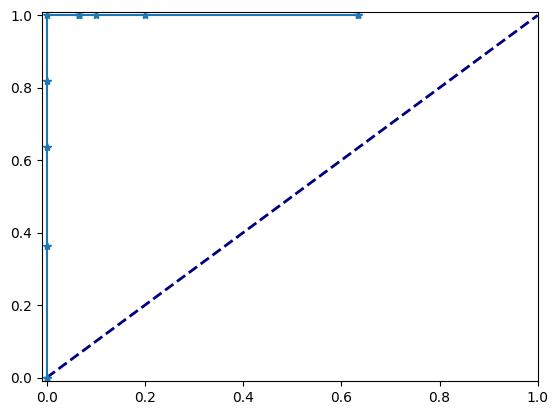

0.6333333333333333


In [94]:
from matplotlib import pyplot as plt
from sklearn.metrics import auc
TPR = []
FPR = []

for threshold in np.arange(-0.1,1.1,0.1):
  TPR=np.append(TPR,np.sum((y_probs[:,1]>threshold) & (y_test=='Iris-versicolor' )))
  FPR=np.append(FPR,np.sum((y_probs[:,1]>threshold) & (y_test!='Iris-versicolor' )))
n_data=np.size(y_test)
versicolor=np.sum(y_test=='Iris-versicolor')
print(TPR/versicolor)
print(FPR/n_data)

plt.xlim([-0.01, 1.0])
plt.ylim([-0.01, 1.01])
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.plot(FPR/n_data,TPR/versicolor,"*-")
plt.show()

roc_auc = auc(FPR / n_data, TPR / versicolor)
print(roc_auc)

In [95]:
from sklearn.metrics import roc_auc_score

# Calculate multi-class ROC AUC (One-vs-Rest strategy)
auc_score = roc_auc_score(y_test, y_probs, multi_class='ovr', average='macro')
print(f"Overall ROC AUC: {auc_score}")

Overall ROC AUC: 1.0


In [96]:
for threshold in np.arange(-0.1,1.1,0.1):
  TPR=np.append(TPR,np.sum((y_probs[:,0]>threshold) & (y_test=='Iris-setosa' )))
  FPR=np.append(FPR,np.sum((y_probs[:,0]>threshold) & (y_test!='Iris-setosa' )))